In [1]:
import pandas as pd
import matplotlib.pyplot as plt

stocks = pd.read_csv(r"C:\Users\Personal\Downloads\Data Set For Task-20260922T064326Z-1-001\Data Set For Task\2) Stock Prices Data Set.csv")

In [2]:
aapl = stocks[stocks["symbol"] == "AAPL"].copy()
aapl.shape

(1007, 7)

In [3]:
aapl["date"] = pd.to_datetime(aapl["date"])
aapl = aapl.sort_values("date").reset_index(drop=True)
aapl.head()

,symbol,date,open,high,low,close,volume
0,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
1,AAPL,2014-01-03,78.9799,79.0999,77.2042,77.2828,98303870
2,AAPL,2014-01-06,76.7785,78.1142,76.2285,77.7042,103359151
3,AAPL,2014-01-07,77.7599,77.9942,76.8464,77.1481,79432766
4,AAPL,2014-01-08,76.9728,77.9371,76.9556,77.6371,64686685


In [4]:
aapl.shape

(1007, 7)

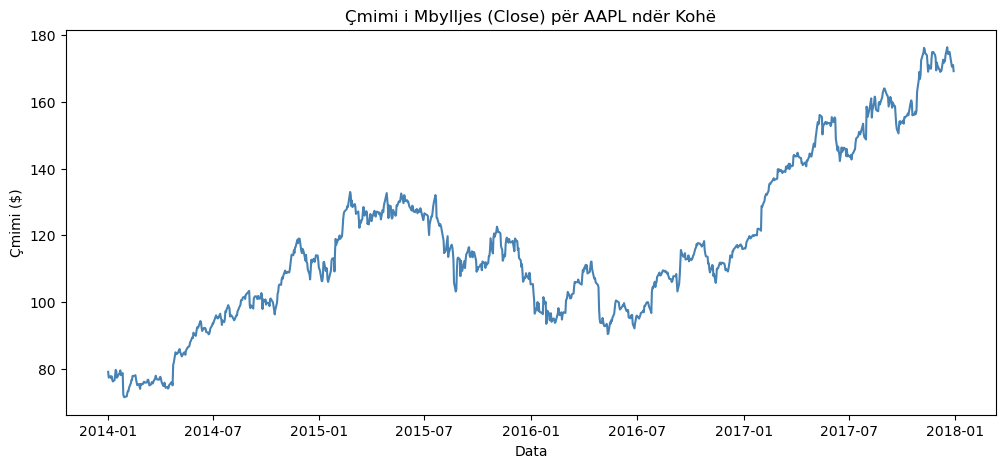

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(aapl["date"], aapl["close"], color="steelblue")
plt.title("Çmimi i Mbylljes (Close) për AAPL ndër Kohë")
plt.xlabel("Data")
plt.ylabel("Çmimi ($)")
plt.savefig("timeseries_aapl_close.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [7]:
aapl_ts = aapl.set_index("date")["close"]
aapl_ts.head()

date
2014-01-02    79.0185
2014-01-03    77.2828
2014-01-06    77.7042
2014-01-07    77.1481
2014-01-08    77.6371
Name: close, dtype: float64

In [8]:
decomposition = seasonal_decompose(aapl_ts, model="additive", period=252)

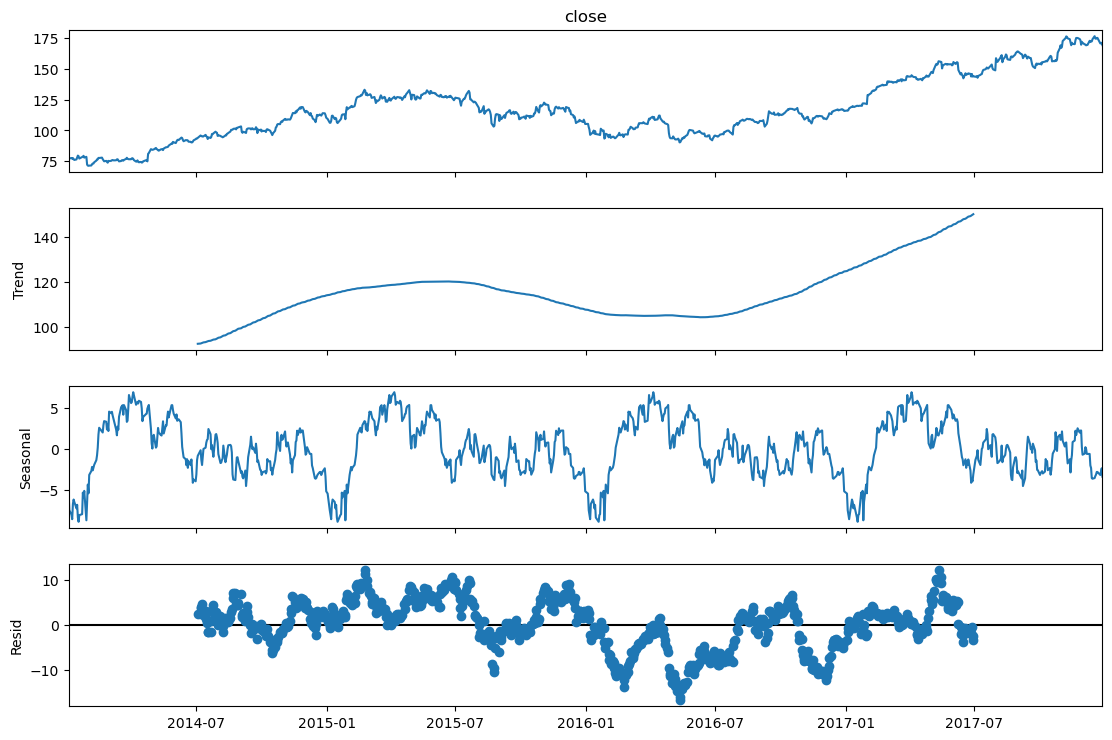

In [9]:
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.savefig("timeseries_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
aapl["MA30"] = aapl["close"].rolling(window=30).mean()

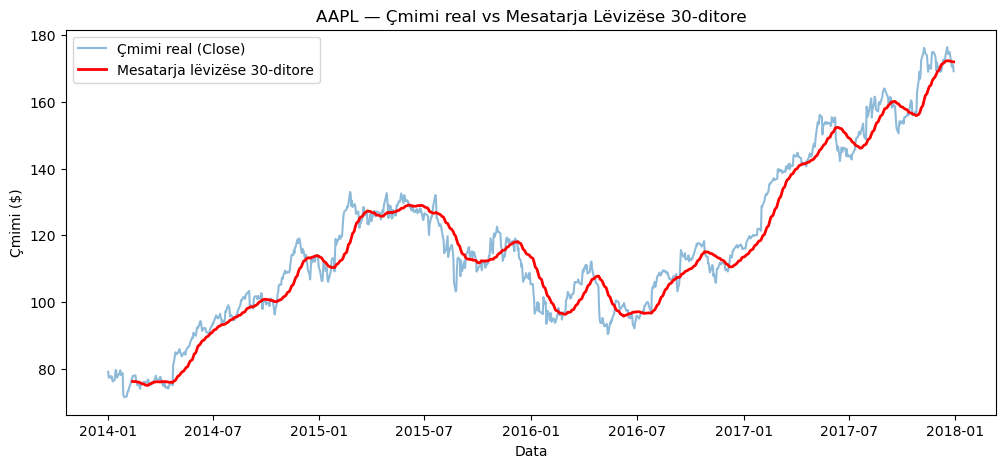

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(aapl["date"], aapl["close"], label="Çmimi real (Close)", alpha=0.5)
plt.plot(aapl["date"], aapl["MA30"], label="Mesatarja lëvizëse 30-ditore", color="red", linewidth=2)
plt.title("AAPL — Çmimi real vs Mesatarja Lëvizëse 30-ditore")
plt.xlabel("Data")
plt.ylabel("Çmimi ($)")
plt.legend()
plt.savefig("timeseries_moving_average.png", dpi=150, bbox_inches="tight")
plt.show()